In [1]:
## 1. Instalación e importación de librerías

In [2]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlxtend networkx

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path(".")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
print("Librerías cargadas.")
print("Carpeta de trabajo:", Path.cwd())
print("Carpeta de salidas:", OUTPUT_DIR.resolve())

Librerías cargadas.
Carpeta de trabajo: C:\Windows\System32
Carpeta de salidas: C:\Windows\System32\output


In [4]:
## 2. Carga de los tres datasets

In [5]:

from pathlib import Path

DATA_DIR = Path(r"C:\Users\jeimy\OneDrive\Documentos\Parcial_DMD")

print("¿Existe la carpeta?", DATA_DIR.exists())
print("Archivos encontrados:")

for archivo in DATA_DIR.iterdir():
    print(archivo.name)


¿Existe la carpeta? True
Archivos encontrados:
.ipynb_checkpoints
comerciantes_mercado.csv
desafio_mercado_central.ipynb
output
quiebra_mercado.csv
transacciones_mercado.csv


In [6]:
transacciones = pd.read_csv(DATA_DIR / "transacciones_mercado.csv", encoding="utf-8")
comerciantes = pd.read_csv(DATA_DIR / "comerciantes_mercado.csv", encoding="utf-8")
quiebra = pd.read_csv(DATA_DIR / "quiebra_mercado.csv", encoding="utf-8")

print("Transacciones:", transacciones.shape)
print("Comerciantes:", comerciantes.shape)
print("Quiebra:", quiebra.shape)

display(transacciones.head())
display(comerciantes.head())
display(quiebra.head())

Transacciones: (1000, 6)
Comerciantes: (500, 19)
Quiebra: (800, 20)


,transaccion_id,fecha,hora,metodo_pago,total_usd,productos
0,T0001,2026-07-26,13:30,Efectivo,12.61,Maíz Blanco; Queso Fresco; Chicharrón; Loroco;...
1,T0002,2026-07-03,12:00,Efectivo,40.60,Maíz Blanco; Queso Fresco; Chicharrón; Loroco;...
2,T0003,2026-07-05,17:30,Cheque,13.22,Yuca; Chicharrón; Repollo; Tomate; Chile Verde...
3,T0004,2026-06-20,09:15,Tarjeta,22.26,Yuca; Chicharrón; Repollo; Tomate; Chile Verde
4,T0005,2026-06-19,15:45,Efectivo,14.23,Frijol Rojo; Queso Fresco; Crema Salvadoreña; ...


,comerciante_id,nombre_negocio,rubro,anios_operacion,antiguedad_local,ubicacion,empleados,ingreso_mensual_usd,egreso_mensual_usd,m2_local,tiene_almacen,vende_online,acepta_tarjeta,horario_extendido,ahorro_previo_usd,deuda_actual_usd,quejas_clientes_3m,edad_comerciante,nivel_educativo
0,C001,Los La Unión Viveres,Textiles,5,2,Norte,1,2896,2101,11,No,No,Sí,No,2692,583,4,41,Básico
1,C002,Casa Guadalupe Viveres,Misceláneos,18,9,Centro,7,2023,1271,36,Sí,No,Sí,No,6006,661,4,40,Básico
2,C003,El Sonsonate Tienda,Textiles,18,3,Oeste,4,4022,2601,13,Sí,Sí,No,No,16048,501,0,69,Básico
3,C004,Mi Rosario Viveres,Misceláneos,1,1,Centro,0,608,472,19,No,No,Sí,No,1276,378,1,31,Básico
4,C005,La Esperanza Multi,Misceláneos,8,2,Centro,2,1780,1100,17,No,No,No,No,2080,4347,0,46,Superior


,registro_id,comerciante_id,anios_operacion,rubro,ubicacion,ingreso_promedio_3m_usd,variacion_ingreso_pct,deuda_actual_usd,ahorro_previo_usd,tiene_seguro,recibio_credito_pandemia,pandemia_caida_ventas_pct,post_pandemia_recuperacion_pct,edad_comerciante,nivel_educativo,numero_empleados,ventas_diarias_promedio,clientes_diarios,margen_ganancia_pct,quiebra_6m
0,R0001,C042,8,Panadería,Centro,2977,9.37,553,12998,No,Sí,46.60,76.16,50,Medio,2,6,17,42.00,0
1,R0002,C160,12,Comida Rápida,Este,5115,-39.36,436,23525,No,Sí,53.04,58.60,25,Primaria,2,11,59,43.09,1
2,R0003,C252,15,Textiles,Oeste,2412,32.91,105,2524,Sí,No,66.66,48.33,48,Superior,8,7,31,15.20,0
3,R0004,C179,2,Textiles,Este,2315,-43.91,474,8968,No,No,32.69,86.33,38,Medio,2,6,16,40.52,1
4,R0005,C125,20,Comida Rápida,Sur,7191,-29.55,92,15712,No,No,44.38,93.80,71,Básico,2,13,44,32.18,0


In [7]:
## 3. Exploración inicial (EDA) y calidad de datos

In [8]:
datasets = {
    "Transacciones": transacciones,
    "Comerciantes": comerciantes,
    "Quiebra": quiebra
}

for nombre, datos in datasets.items():
    print("\\n" + "="*70)
    print(nombre, "| dimensiones:", datos.shape)
    print("\\nTipos de datos:")
    display(datos.dtypes.astype(str).to_frame("tipo"))
    print("Duplicados completos:", datos.duplicated().sum())
    print("Valores faltantes por columna:")
    display(datos.isna().sum().to_frame("faltantes"))
    print("Estadísticas descriptivas:")
    display(datos.describe(include="all").T)

\n======================================================================
Transacciones | dimensiones: (1000, 6)
\nTipos de datos:


,tipo
transaccion_id,str
fecha,str
hora,str
metodo_pago,str
total_usd,float64
productos,str


Duplicados completos: 0
Valores faltantes por columna:


,faltantes
transaccion_id,0
fecha,0
hora,0
metodo_pago,0
total_usd,0
productos,0


Estadísticas descriptivas:


...

,tipo
registro_id,str
comerciante_id,str
anios_operacion,int64
rubro,str
ubicacion,str
ingreso_promedio_3m_usd,int64
variacion_ingreso_pct,float64
deuda_actual_usd,int64
ahorro_previo_usd,int64
tiene_seguro,str


Duplicados completos: 0
Valores faltantes por columna:


,faltantes
registro_id,0
comerciante_id,0
anios_operacion,0
rubro,0
ubicacion,0
ingreso_promedio_3m_usd,0
variacion_ingreso_pct,0
deuda_actual_usd,0
ahorro_previo_usd,0
tiene_seguro,0


Estadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
registro_id,800,800,R0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
comerciante_id,800,397,C058,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anios_operacion,800.0,NaN,NaN,NaN,10.8825,9.706001,1.0,3.0,8.0,18.0,40.0
rubro,800,8,Abarrotes,156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ubicacion,800,5,Centro,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ingreso_promedio_3m_usd,800.0,NaN,NaN,NaN,2496.10375,1125.383801,432.0,1661.0,2264.5,3181.25,7191.0
variacion_ingreso_pct,800.0,NaN,NaN,NaN,0.210025,25.098341,-49.57,-19.64,3.27,20.8225,39.92
deuda_actual_usd,800.0,NaN,NaN,NaN,1166.59,1332.851058,1.0,310.75,589.5,1635.0,4959.0
ahorro_previo_usd,800.0,NaN,NaN,NaN,5504.32375,4156.597967,482.0,2546.0,4323.0,7397.0,24284.0
tiene_seguro,800,2,No,680,NaN,NaN,NaN,NaN,NaN,NaN,NaN


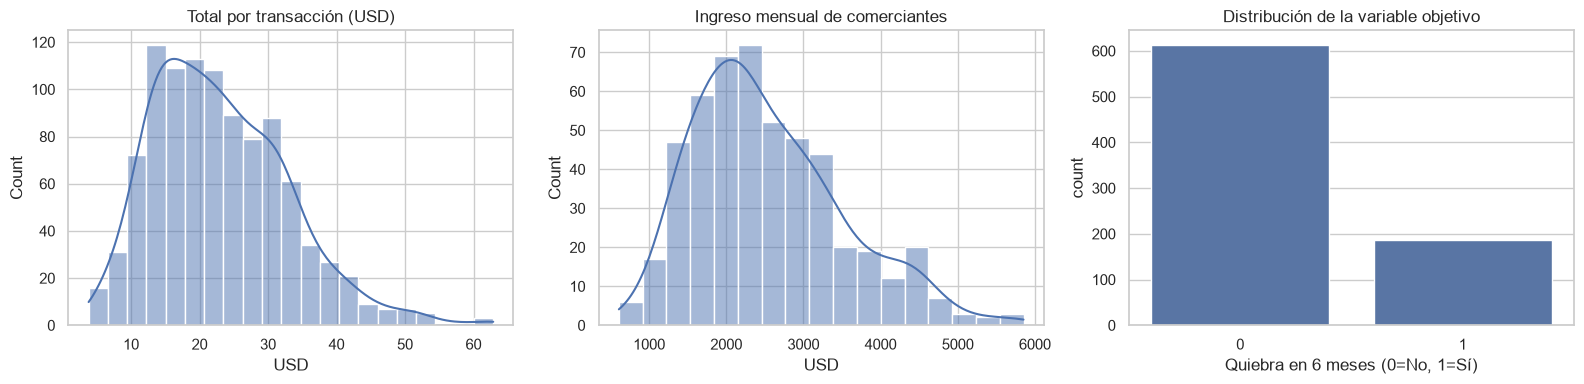

In [9]:
# Distribuciones básicas para apoyar el EDA
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(transacciones["total_usd"], kde=True, ax=axes[0])
axes[0].set_title("Total por transacción (USD)")
axes[0].set_xlabel("USD")

sns.histplot(comerciantes["ingreso_mensual_usd"], kde=True, ax=axes[1])
axes[1].set_title("Ingreso mensual de comerciantes")
axes[1].set_xlabel("USD")

sns.countplot(data=quiebra, x="quiebra_6m", ax=axes[2])
axes[2].set_title("Distribución de la variable objetivo")
axes[2].set_xlabel("Quiebra en 6 meses (0=No, 1=Sí)")

plt.tight_layout()
plt.show()

## RETO 1: Reglas de asociación con Apriori

In [11]:
# Preparar las cestas de compra
transacciones["productos_lista"] = (
    transacciones["productos"]
    .fillna("")
    .apply(lambda x: [p.strip() for p in x.split(";") if p.strip()])
)

te = TransactionEncoder()
matriz = te.fit(transacciones["productos_lista"]).transform(transacciones["productos_lista"])
basket = pd.DataFrame(matriz, columns=te.columns_)

print("Matriz transaccional:", basket.shape)
print("Productos únicos:", basket.shape[1])
display(basket.sum().sort_values(ascending=False).head(15).to_frame("frecuencia"))

Matriz transaccional: (1000, 48)
Productos únicos: 48


,frecuencia
Tomate,554
Repollo,406
Chile Verde,350
Café en Grano,331
Queso Fresco,302
Frijol Rojo,246
Cebolla,244
Huevos,239
Chicharrón,232
Sal,225


In [12]:
# Apriori y reglas de asociación
itemsets = apriori(basket, min_support=0.05, use_colnames=True)
print("Itemsets frecuentes encontrados:", len(itemsets))

if itemsets.empty:
    raise ValueError("No se encontraron itemsets con soporte >= 0.05. Revisa el formato de la columna productos.")

reglas = association_rules(itemsets, metric="confidence", min_threshold=0.30)

if reglas.empty:
    print("No se generaron reglas con confianza >= 0.30. No hay reglas que cumplan ambos umbrales.")
else:
    reglas["antecedents_txt"] = reglas["antecedents"].apply(lambda x: ", ".join(sorted(x)))
    reglas["consequents_txt"] = reglas["consequents"].apply(lambda x: ", ".join(sorted(x)))
    columnas_metricas = ["antecedents_txt", "consequents_txt", "support", "confidence", "lift", "conviction", "leverage"]
    top10_reglas = reglas.sort_values("lift", ascending=False).head(10)[columnas_metricas].reset_index(drop=True)
    display(top10_reglas.style.format({
        "support":"{:.3f}", "confidence":"{:.3f}", "lift":"{:.3f}",
        "conviction":"{:.3f}", "leverage":"{:.3f}"
    }))
    top10_reglas.to_csv(OUTPUT_DIR / "top_10_reglas_apriori.csv", index=False)

Itemsets frecuentes encontrados: 1465


,antecedents_txt,consequents_txt,support,confidence,lift,conviction,leverage
0,"Aceite, Café en Grano, Jabón Lavadero","Azúcar, Detergente",0.065,0.985,14.699,61.578,0.061
1,"Azúcar, Detergente","Aceite, Café en Grano, Jabón Lavadero",0.065,0.970,14.699,31.289,0.061
2,"Azúcar, Detergente","Huevos, Jabón Lavadero",0.064,0.955,14.696,20.882,0.060
3,"Huevos, Jabón Lavadero","Azúcar, Detergente",0.064,0.985,14.696,60.645,0.060
4,"Aceite, Frijol Rojo, Jabón Lavadero","Azúcar, Detergente",0.064,0.985,14.696,60.645,0.060
5,"Aceite, Azúcar, Detergente","Frijol Rojo, Jabón Lavadero",0.064,0.955,14.696,20.882,0.060
6,"Frijol Rojo, Jabón Lavadero","Aceite, Azúcar, Detergente",0.064,0.985,14.696,60.645,0.060
7,"Azúcar, Detergente","Aceite, Frijol Rojo, Jabón Lavadero",0.064,0.955,14.696,20.882,0.060
8,"Aceite, Huevos, Jabón Lavadero","Azúcar, Detergente",0.064,0.985,14.696,60.645,0.060
9,"Aceite, Azúcar, Detergente","Huevos, Jabón Lavadero",0.064,0.955,14.696,20.882,0.060


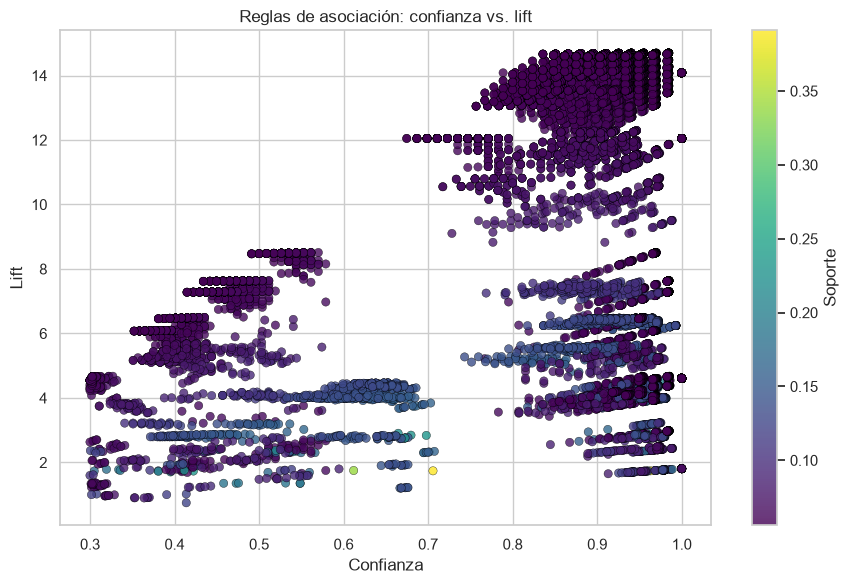

In [13]:
# Gráfico de dispersión: confianza (X), lift (Y), color = soporte
if not reglas.empty:
    plt.figure(figsize=(9, 6))
    sc = plt.scatter(reglas["confidence"], reglas["lift"], c=reglas["support"], cmap="viridis", alpha=0.8, edgecolor="black", linewidth=0.3)
    plt.colorbar(sc, label="Soporte")
    plt.xlabel("Confianza")
    plt.ylabel("Lift")
    plt.title("Reglas de asociación: confianza vs. lift")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "top_lift.png", dpi=200, bbox_inches="tight")
    plt.show()

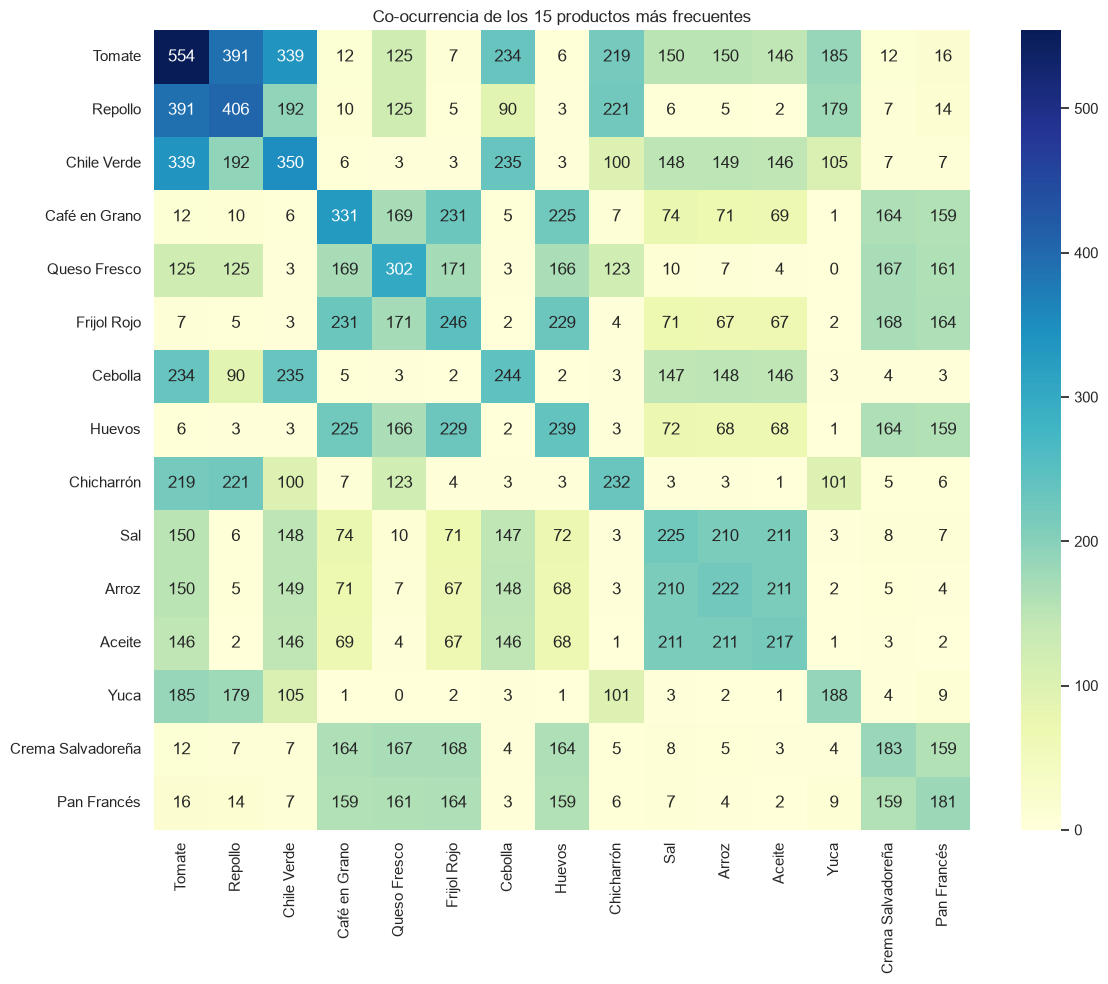

In [14]:
# Heatmap de co-ocurrencia para los 15 productos más frecuentes
frecuencias = basket.sum().sort_values(ascending=False)
top15 = frecuencias.head(15).index.tolist()
coocurrencia = basket[top15].astype(int).T.dot(basket[top15].astype(int))

plt.figure(figsize=(12, 10))
sns.heatmap(coocurrencia, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Co-ocurrencia de los 15 productos más frecuentes")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "coocurrencia_top15.png", dpi=200, bbox_inches="tight")
plt.show()

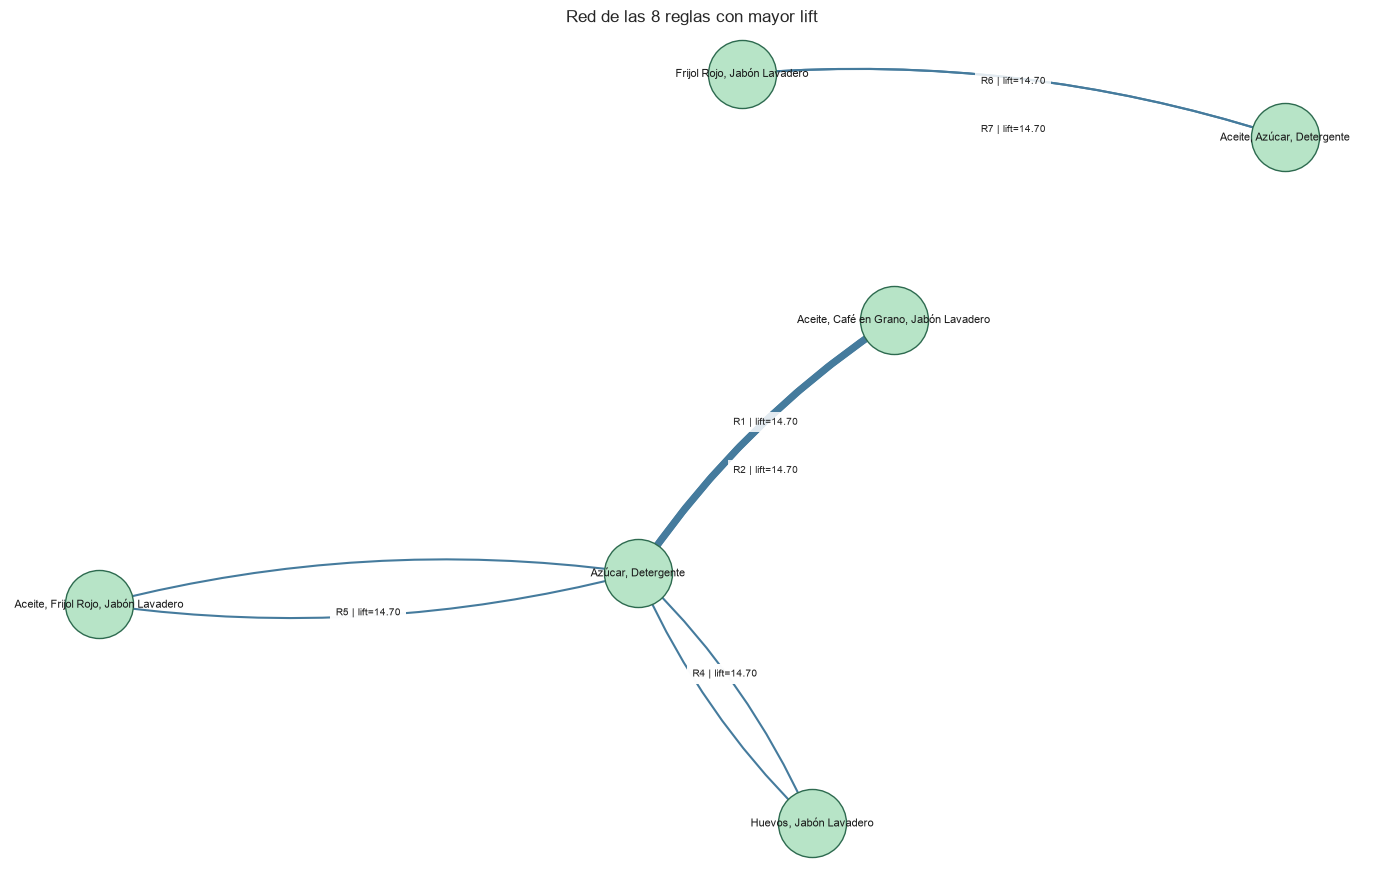

In [37]:
# Red legible de las 8 reglas con mayor lift
if not reglas.empty:
    top8 = reglas.sort_values("lift", ascending=False).head(8)
    G = nx.MultiDiGraph()
    for i, (_, r) in enumerate(top8.iterrows(), 1):
        ant = ", ".join(sorted(r["antecedents"])); cons = ", ".join(sorted(r["consequents"]))
        G.add_edge(ant, cons, key=i, support=float(r["support"]), lift=float(r["lift"]), regla=i)

    plt.figure(figsize=(14, 9))
    pos = nx.spring_layout(G, seed=RANDOM_STATE, k=2.2, iterations=100)
    nx.draw_networkx_nodes(G, pos, node_size=2400, node_color="#b7e4c7", edgecolors="#2d6a4f")
    nx.draw_networkx_labels(G, pos, font_size=8)

    edges = list(G.edges(keys=True, data=True))
    soportes = [d["support"] for _, _, _, d in edges]
    mn, mx = min(soportes), max(soportes)
    for j, (u, v, k, d) in enumerate(edges):
        grosor = 1.5 + 3.5*(d["support"]-mn)/(mx-mn) if mx > mn else 2.5
        nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], width=grosor, edge_color="#457b9d",
                               arrows=True, arrowsize=14, connectionstyle=f"arc3,rad={0.10 if j%2==0 else -0.10}")
        x1, y1 = pos[u]; x2, y2 = pos[v]
        x, y = (x1+x2)/2, (y1+y2)/2 + (0.06 if j%2==0 else -0.06)
        plt.text(x, y, f"R{d['regla']} | lift={d['lift']:.2f}",
                 fontsize=7, ha="center", va="center",
                 bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"))

    plt.title("Red de las 8 reglas con mayor lift")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "red_reglas_top8.png", dpi=200, bbox_inches="tight")
    plt.show()


### Interpretación del Reto 1

**Estrategia 1.** Promoción combinada de productos básicos y de limpieza:
Hallazgo: Las reglas de asociación identifican una relación entre azúcar, detergente, productos en grano y jabón lavadero. Algunas reglas presentan una confianza superior al 95% y un lift cercano a 14.70.

Acción propuesta: Crear una promoción que combine azúcar y detergente con productos en grano o jabón lavadero. También se puede colocar esta selección en una zona cercana del puesto para facilitar que los clientes encuentren los productos relacionados.

Justificación: Las asociaciones detectadas sugieren que estos productos aparecen juntos con mayor frecuencia de la esperada si fueran independientes. La promoción debe probarse durante un periodo limitado para medir si aumenta el valor promedio de compra.

**Estrategia 2.** Exhibición conjunta de aceite y productos complementarios:
Hallazgo: Entre las reglas principales aparecen combinaciones que incluyen aceite, azúcar y detergente, así como asociaciones con productos en grano y jabón lavadero.

Acción propuesta: Probar una exhibición conjunta de aceite y productos complementarios identificados en las reglas, utilizando señalización sencilla para incentivar compras adicionales sin obligar al cliente a adquirir paquetes completos.

Justificación: La asociación entre los productos puede ayudar a diseñar una exhibición más conveniente para los consumidores. Se recomienda comparar las ventas antes y después de implementar la estrategia para evaluar su efectividad.

**Estrategia 3.** Venta cruzada de huevos y jabón lavadero con productos frecuentes en las reglas:
Hallazgo: El archivo de reglas incluye asociaciones entre huevos y jabón lavadero, junto con azúcar y detergente, con una confianza aproximada del 95.5% en una de las reglas.

Acción propuesta: Realizar una prueba de venta cruzada en la que se sugieran productos complementarios cuando el cliente compre los artículos indicados por las reglas. La recomendación puede realizarse verbalmente o mediante pequeños carteles en los puestos participantes.

Justificación: Esta estrategia aprovecha los patrones de compra observados para facilitar compras complementarias. Su implementación debe evaluarse mediante el número de productos por transacción y el valor promedio de compra, sin asumir que la asociación garantiza un incremento en las ventas.

## RETO 2: Segmentación de comerciantes con K-Means

In [18]:
# Preparar variables para K-Means
datos_km = comerciantes.drop(columns=["comerciante_id", "nombre_negocio"], errors="ignore").copy()

binarias = [c for c in ["tiene_almacen", "vende_online", "acepta_tarjeta", "horario_extendido"] if c in datos_km.columns]
for c in binarias:
    datos_km[c] = datos_km[c].astype(str).str.strip().str.capitalize().replace({"Si":"Sí", "No":"No"})

cat_cols = datos_km.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = datos_km.select_dtypes(include=np.number).columns.tolist()

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocesador_km = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", onehot)]), cat_cols)
])

X_km = preprocesador_km.fit_transform(datos_km)
print("Dimensiones después del preprocesamiento:", X_km.shape)
print("Variables numéricas:", num_cols)
print("Variables categóricas:", cat_cols)

C:\Users\jeimy\AppData\Local\Temp\ipykernel_7984\1752370564.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = datos_km.select_dtypes(include=["object", "category"]).columns.tolist()


Dimensiones después del preprocesamiento: (500, 35)
Variables numéricas: ['anios_operacion', 'antiguedad_local', 'empleados', 'ingreso_mensual_usd', 'egreso_mensual_usd', 'm2_local', 'ahorro_previo_usd', 'deuda_actual_usd', 'quejas_clientes_3m', 'edad_comerciante']
Variables categóricas: ['rubro', 'ubicacion', 'tiene_almacen', 'vende_online', 'acepta_tarjeta', 'horario_extendido', 'nivel_educativo']


In [19]:
# Método del codo (inercia), silueta, Calinski-Harabasz y Davies-Bouldin
ks = list(range(2, 11))
inertias = []
silhouettes = []
calinski = []
davies = []

# El codo incluye K=1
for k in range(1, 11):
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    model.fit(X_km)
    inertias.append(model.inertia_)

for k in ks:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_km)
    silhouettes.append(silhouette_score(X_km, labels))
    calinski.append(calinski_harabasz_score(X_km, labels))
    davies.append(davies_bouldin_score(X_km, labels))

metricas_k = pd.DataFrame({
    "K": ks,
    "Silhouette": silhouettes,
    "Calinski-Harabasz": calinski,
    "Davies-Bouldin": davies
})
display(metricas_k.round(4))

,K,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0.1586,92.2385,2.2535
1,3,0.1087,61.6462,2.7756
2,4,0.1057,51.8302,2.5357
3,5,0.0990,46.6737,2.4474
4,6,0.0755,42.3478,2.4307
5,7,0.0843,38.5984,2.2959
6,8,0.0666,36.6410,2.4145
7,9,0.0661,34.4298,2.3623
8,10,0.0721,32.3255,2.3316


In [20]:
# Gap Statistic con 10 conjuntos de referencia uniformes
def gap_statistic(X, ks=range(2, 11), n_refs=10, random_state=42):
    rng = np.random.default_rng(random_state)
    X = np.asarray(X)
    mins = X.min(axis=0)
    maxs = X.max(axis=0)
    gaps, sk_values = [], []
    for k in ks:
        ref_inertias = []
        for _ in range(n_refs):
            X_ref = rng.uniform(mins, maxs, size=X.shape)
            km_ref = KMeans(n_clusters=k, n_init=10, random_state=random_state)
            km_ref.fit(X_ref)
            ref_inertias.append(max(km_ref.inertia_, 1e-12))
        km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        km.fit(X)
        log_ref = np.log(ref_inertias)
        gap = np.mean(log_ref) - np.log(max(km.inertia_, 1e-12))
        sk = np.sqrt(1 + 1 / n_refs) * np.std(log_ref, ddof=1)
        gaps.append(gap)
        sk_values.append(sk)
    return pd.DataFrame({"K": list(ks), "Gap": gaps, "Gap_error": sk_values})

gap_df = gap_statistic(X_km, ks=ks, n_refs=10, random_state=RANDOM_STATE)
display(gap_df.round(4))

# K sugerido por cada método
k_codo = int(np.argmax(np.abs(np.diff(inertias, n=2))) + 2)  # heurística basada en segunda diferencia
k_silueta = int(metricas_k.loc[metricas_k["Silhouette"].idxmax(), "K"])
k_gap = int(gap_df.loc[gap_df["Gap"].idxmax(), "K"])

comparacion_k = pd.DataFrame({
    "Método": ["Codo (segunda diferencia, heurística)", "Silueta (máxima)", "Gap Statistic (máximo)"],
    "K sugerido": [k_codo, k_silueta, k_gap]
})
display(comparacion_k)

,K,Gap,Gap_error
0,2,0.7038,0.0128
1,3,0.6892,0.0087
2,4,0.6828,0.0147
3,5,0.6848,0.0120
4,6,0.6922,0.0074
5,7,0.6894,0.0086
6,8,0.6930,0.0133
7,9,0.6962,0.0173
8,10,0.6890,0.0139


,Método,K sugerido
0,"Codo (segunda diferencia, heurística)",2
1,Silueta (máxima),2
2,Gap Statistic (máximo),2


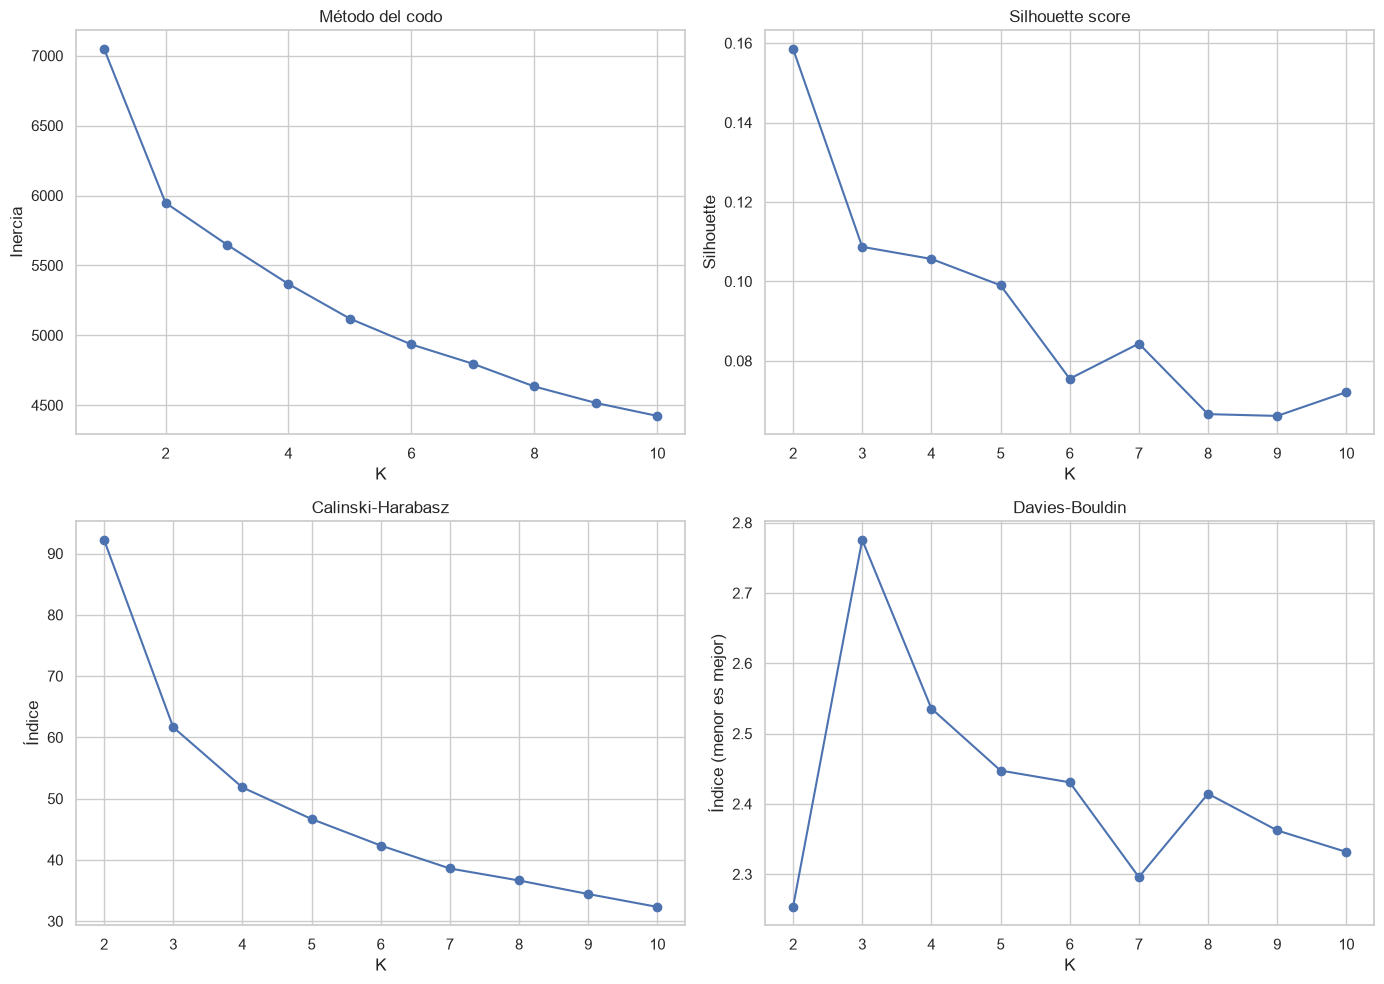

In [38]:
# Gráfico 2x2 solicitado
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0,0].plot(range(1, 11), inertias, marker="o")
axes[0,0].set_title("Método del codo")
axes[0,0].set_xlabel("K"); axes[0,0].set_ylabel("Inercia")

axes[0,1].plot(ks, silhouettes, marker="o")
axes[0,1].set_title("Silhouette score")
axes[0,1].set_xlabel("K"); axes[0,1].set_ylabel("Silhouette")

axes[1,0].plot(ks, calinski, marker="o")
axes[1,0].set_title("Calinski-Harabasz")
axes[1,0].set_xlabel("K"); axes[1,0].set_ylabel("Índice")

axes[1,1].plot(ks, davies, marker="o")
axes[1,1].set_title("Davies-Bouldin")
axes[1,1].set_xlabel("K"); axes[1,1].set_ylabel("Índice (menor es mejor)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "matriz_seleccion_k.png", dpi=200, bbox_inches="tight")
plt.show()

In [22]:
K_FINAL = k_silueta
print("K final utilizado:", K_FINAL)

kmeans_final = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=10, random_state=RANDOM_STATE)
clusters = kmeans_final.fit_predict(X_km)

comerciantes_cluster = comerciantes.copy()
comerciantes_cluster["cluster"] = clusters
display(comerciantes_cluster.groupby("cluster").size().to_frame("cantidad_comerciantes"))

K final utilizado: 2


,cantidad_comerciantes
cluster,
0,198
1,302


Silhouette: 0.1586
Calinski-Harabasz: 92.2385
Davies-Bouldin: 2.2535


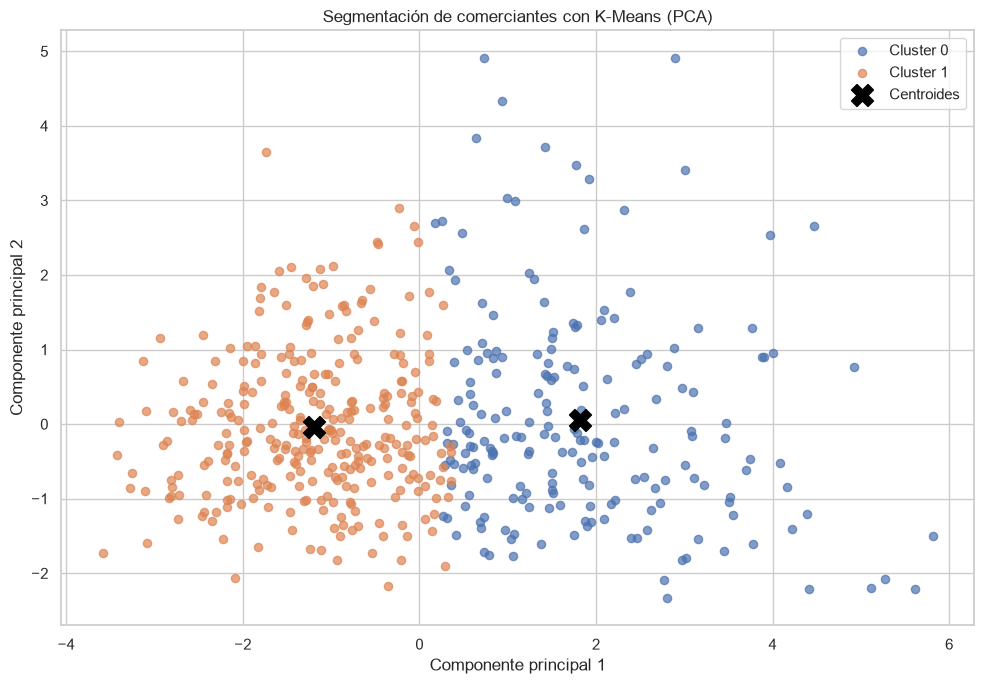

Varianza explicada por PCA: [0.2291 0.0967]


In [23]:
# Validación adicional para el modelo final
labels_final = kmeans_final.labels_
print("Silhouette:", round(silhouette_score(X_km, labels_final), 4))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_km, labels_final), 4))
print("Davies-Bouldin:", round(davies_bouldin_score(X_km, labels_final), 4))

# PCA a 2 dimensiones para visualizar los clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_km)
centroides_pca = pca.transform(kmeans_final.cluster_centers_)

plt.figure(figsize=(10, 7))
for cl in sorted(np.unique(clusters)):
    mask = clusters == cl
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f"Cluster {cl}", alpha=0.7, s=35)
plt.scatter(centroides_pca[:, 0], centroides_pca[:, 1], marker="X", s=250, c="black", label="Centroides")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Segmentación de comerciantes con K-Means (PCA)")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kmeans_clusters.png", dpi=200, bbox_inches="tight")
plt.show()
print("Varianza explicada por PCA:", pca.explained_variance_ratio_.round(4))

In [39]:
# Perfilamiento de clusters
perfil = comerciantes_cluster.groupby("cluster").agg(
    cantidad=("cluster", "size"),
    ingreso_promedio_usd=("ingreso_mensual_usd", "mean"),
    edad_promedio=("edad_comerciante", "mean"),
    antiguedad_promedio=("anios_operacion", "mean"),
    deuda_promedio_usd=("deuda_actual_usd", "mean"),
    empleados_promedio=("empleados", "mean"),
    pct_acepta_tarjeta=("acepta_tarjeta", lambda s: (s.astype(str).str.strip().str.lower().isin(["sí","si","yes","1","true"])).mean()*100),
    pct_vende_online=("vende_online", lambda s: (s.astype(str).str.strip().str.lower().isin(["sí","si","yes","1","true"])).mean()*100),
    pct_tiene_almacen=("tiene_almacen", lambda s: (s.astype(str).str.strip().str.lower().isin(["sí","si","yes","1","true"])).mean()*100)
).round(2)
display(perfil)
perfil.to_csv(OUTPUT_DIR / "perfil_clusters.csv")

,cantidad,ingreso_promedio_usd,edad_promedio,antiguedad_promedio,deuda_promedio_usd,empleados_promedio,pct_acepta_tarjeta,pct_vende_online,pct_tiene_almacen
cluster,,,,,,,,,
0,198,3455.01,44.96,17.30,1317.38,3.14,47.47,33.84,43.43
1,302,1941.08,42.85,6.65,1074.01,1.58,25.50,24.83,25.50


In [40]:
# Estabilidad: 20 inicializaciones distintas y comparación random vs k-means++
resultados_estabilidad = []
centroides_runs = []

for seed in range(20):
    km = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=1, random_state=seed)
    km.fit(X_km)
    resultados_estabilidad.append({"seed": seed, "inercia": km.inertia_})
    centroides_runs.append(km.cluster_centers_)

estabilidad_df = pd.DataFrame(resultados_estabilidad)
print("Desviación estándar de la inercia (20 inicializaciones):", round(estabilidad_df["inercia"].std(ddof=1), 4))

# Comparar inicialización random y k-means++ usando n_init=10
comparacion_init = []
for init in ["random", "k-means++"]:
    km = KMeans(n_clusters=K_FINAL, init=init, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_km)
    comparacion_init.append({"inicializacion": init, "inercia": km.inertia_})
display(pd.DataFrame(comparacion_init))

# Variabilidad promedio de centroides entre corridas (distancia al centroide medio por índice de cluster)
centroides_runs = np.array(centroides_runs)
centroides_promedio = centroides_runs.mean(axis=0)
variabilidad_centroides = np.sqrt(((centroides_runs - centroides_promedio) ** 2).sum(axis=2)).mean()
print("Variabilidad promedio de centroides:", round(float(variabilidad_centroides), 4))

Desviación estándar de la inercia (20 inicializaciones): 0.0659


,inicializacion,inercia
0,random,5947.745108
1,k-means++,5947.770760


Variabilidad promedio de centroides: 1.28


### Interpretación y programas de apoyo — Reto 2

El algoritmo K-Means agrupó a los 500 comerciantes en dos segmentos. El clúster 0 contiene 198 comerciantes y presenta un ingreso promedio de $3,455.01, una antigüedad de 17.3 años y 3.14 empleados en promedio. Además, el 47.47% acepta pagos con tarjeta y el 33.84% vende en línea. Estas características corresponden a negocios de mayor escala y trayectoria comercial.

El clúster 1 contiene 302 comerciantes, con un ingreso promedio de $1,941.08, una antigüedad de 6.65 años y 1.58 empleados en promedio. El 25.5% acepta pagos con tarjeta y el 24.83% vende en línea. En promedio, este segmento presenta menor escala operativa y menor adopción de algunos canales comerciales.

Las métricas de selección de K favorecieron dos clústeres, aunque el Silhouette Score fue aproximadamente 0.158, lo que sugiere una separación limitada entre los grupos. Por tanto, los perfiles deben interpretarse como tendencias generales y no como categorías rígidas para cada comerciante.

### Programas de apoyo diferenciados por clúster

**Programa 1. Consolidación y expansión comercial — Clúster 0**

Dirigido a los 198 comerciantes con mayores ingresos, antigüedad y cantidad promedio de empleados. Se propone brindar capacitación en fidelización de clientes, gestión financiera, ventas digitales y optimización de inventarios para fortalecer los negocios consolidados y facilitar su crecimiento.

**Programa 2. Fortalecimiento de pequeños negocios — Clúster 1**

Dirigido a los 302 comerciantes con menor ingreso promedio, menor antigüedad y equipos de trabajo más pequeños. Se recomienda ofrecer asesoría en control de costos, fijación de precios, flujo de caja y planificación de compras para mejorar la rentabilidad y la sostenibilidad de sus negocios.

**Programa 3. Digitalización accesible — ambos clústeres**

Promover el uso de herramientas sencillas para recibir pagos electrónicos, publicar catálogos por WhatsApp y gestionar pedidos. La capacitación puede priorizar al clúster 1, ya que presenta una menor proporción de comerciantes que aceptan pagos con tarjeta y venden en línea.

Las propuestas se basan en los perfiles promedio de los clústeres y deben adaptarse a las necesidades individuales de cada comerciante.

## RETO 3: Predicción de quiebra con Árbol de Decisión


In [26]:
# Preparación de variables y partición 70/30 estratificada
objetivo = "quiebra_6m"
columnas_excluir = [c for c in ["quiebra_6m", "registro_id", "comerciante_id"] if c in quiebra.columns]
X = quiebra.drop(columns=columnas_excluir)
y = quiebra[objetivo].astype(int)

categoricas = X.select_dtypes(include=["object", "category"]).columns.tolist()
numericas = X.select_dtypes(include=np.number).columns.tolist()

X = X.copy()
for c in categoricas:
    X[c] = X[c].astype(str).str.strip()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

# Imputación de nulos y one-hot encoding drop_first=True
X_train_num = X_train[numericas].copy()
X_test_num = X_test[numericas].copy()
for c in numericas:
    mediana = X_train_num[c].median()
    X_train_num[c] = X_train_num[c].fillna(mediana)
    X_test_num[c] = X_test_num[c].fillna(mediana)

X_train_cat = pd.get_dummies(X_train[categoricas], drop_first=True, dtype=int)
X_test_cat = pd.get_dummies(X_test[categoricas], drop_first=True, dtype=int)
X_train_model = pd.concat([X_train_num.reset_index(drop=True), X_train_cat.reset_index(drop=True)], axis=1)
X_test_model = pd.concat([X_test_num.reset_index(drop=True), X_test_cat.reset_index(drop=True)], axis=1)
X_test_model = X_test_model.reindex(columns=X_train_model.columns, fill_value=0)

print("Entrenamiento:", X_train_model.shape, "| Prueba:", X_test_model.shape)
print("Distribución de clases total:")
display(y.value_counts(normalize=True).rename("proporción").to_frame())

Entrenamiento: (560, 28) | Prueba: (240, 28)
Distribución de clases total:


C:\Users\jeimy\AppData\Local\Temp\ipykernel_7984\3771548299.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = X.select_dtypes(include=["object", "category"]).columns.tolist()


,proporción
quiebra_6m,
0,0.7675
1,0.2325


In [28]:
# Entrenar el árbol con los hiperparámetros requeridos
arbol = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    min_samples_split=10,
    random_state=RANDOM_STATE
)
arbol.fit(X_train_model, y_train)

y_pred = arbol.predict(X_test_model)
y_prob = arbol.predict_proba(X_test_model)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print("\\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=["Bajo Riesgo (Activo)", "Alto Riesgo (Quiebra)"], zero_division=0))

Accuracy:  0.7458
Precision: 0.4324
Recall:    0.2857
F1-score:  0.3441
ROC-AUC:   0.5992
\nReporte de clasificación:
                       precision    recall  f1-score   support

 Bajo Riesgo (Activo)       0.80      0.89      0.84       184
Alto Riesgo (Quiebra)       0.43      0.29      0.34        56

             accuracy                           0.75       240
            macro avg       0.62      0.59      0.59       240
         weighted avg       0.72      0.75      0.73       240



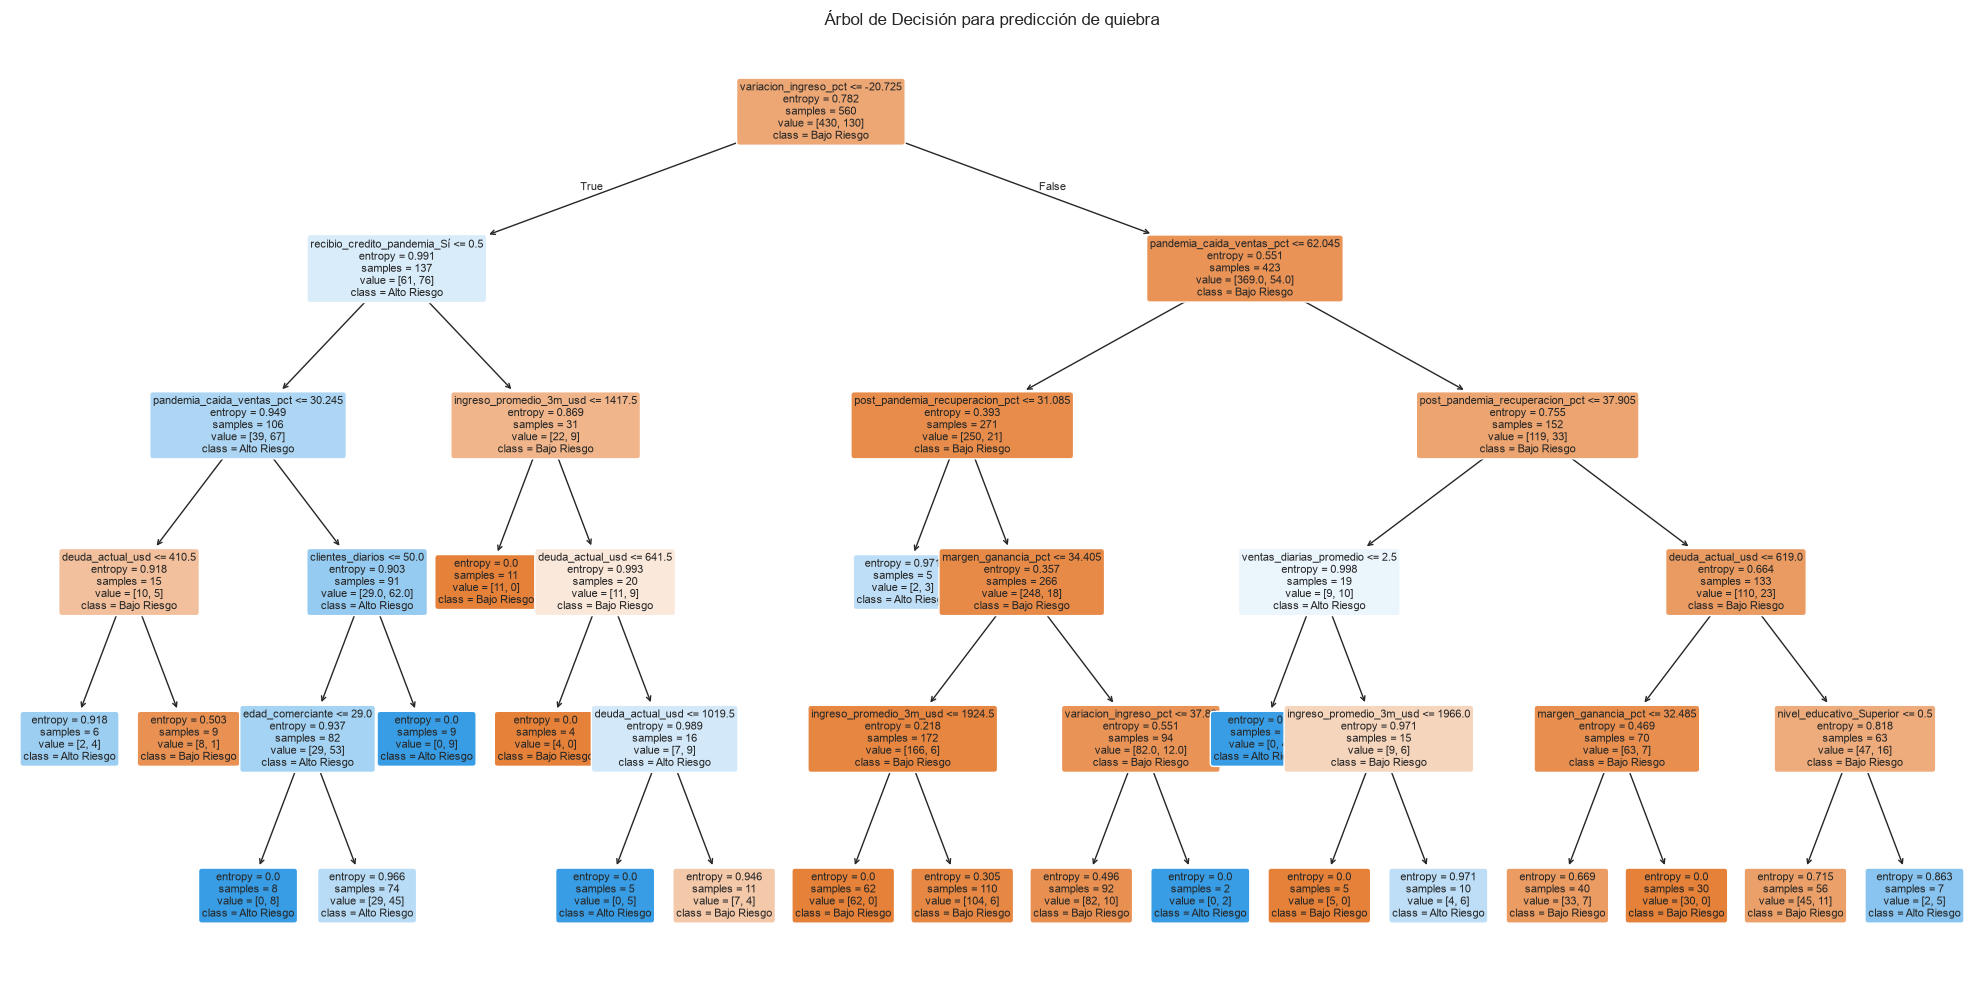

In [29]:
# Árbol completo
plt.figure(figsize=(20, 10))
plot_tree(
    arbol,
    feature_names=X_train_model.columns,
    class_names=["Bajo Riesgo", "Alto Riesgo"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Árbol de Decisión para predicción de quiebra")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "decision_tree.png", dpi=200, bbox_inches="tight")
plt.show()

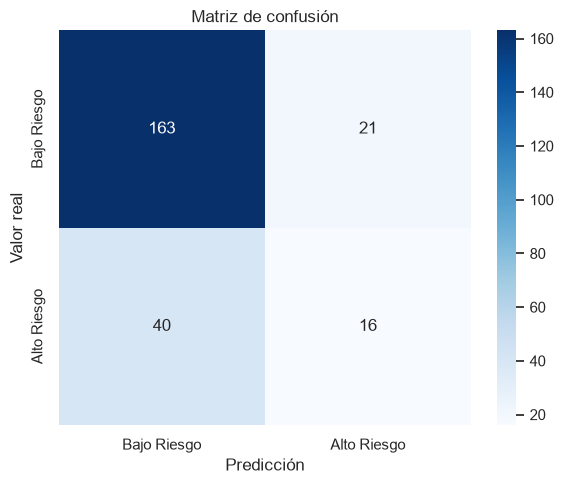

In [30]:
# Matriz de confusión como heatmap
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Bajo Riesgo", "Alto Riesgo"],
            yticklabels=["Bajo Riesgo", "Alto Riesgo"])
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "matriz_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

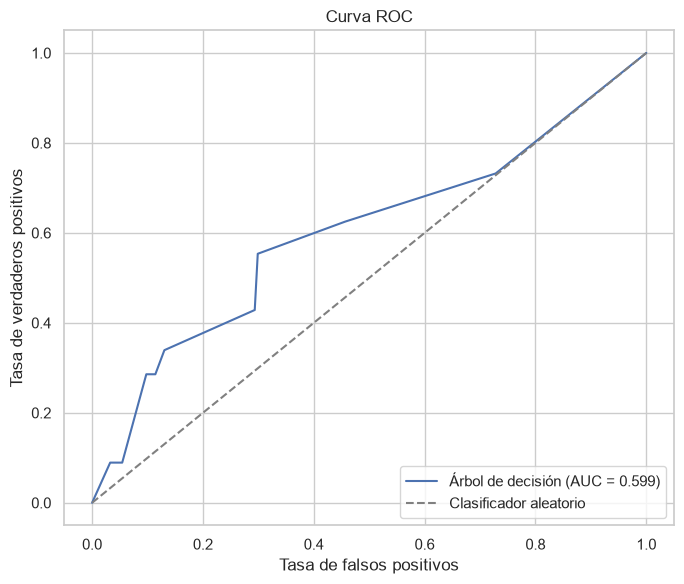

In [31]:
# Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Árbol de decisión (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "curva_roc.png", dpi=200, bbox_inches="tight")
plt.show()

,importancia
variacion_ingreso_pct,0.418753
deuda_actual_usd,0.096062
pandemia_caida_ventas_pct,0.091565
ingreso_promedio_3m_usd,0.088713
post_pandemia_recuperacion_pct,0.078842
margen_ganancia_pct,0.065454
recibio_credito_pandemia_Sí,0.046136
nivel_educativo_Superior,0.030332
edad_comerciante,0.029981
clientes_diarios,0.029625


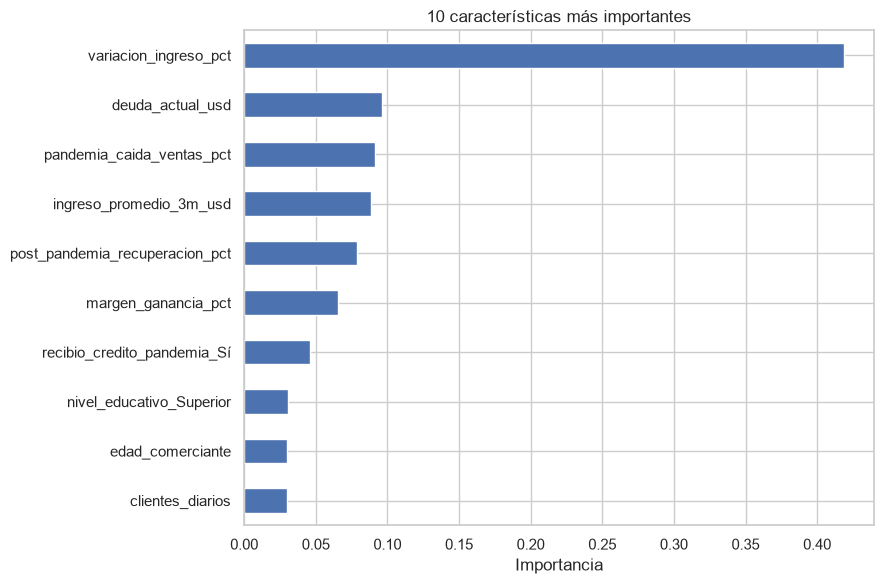

In [32]:
# Importancia de características: top 10
importancias = pd.Series(arbol.feature_importances_, index=X_train_model.columns).sort_values(ascending=False)
display(importancias.head(10).to_frame("importancia"))
plt.figure(figsize=(9, 6))
importancias.head(10).sort_values().plot(kind="barh")
plt.xlabel("Importancia")
plt.title("10 características más importantes")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "importancia_caracteristicas.png", dpi=200, bbox_inches="tight")
plt.show()

In [41]:
# Guardar métricas y predicciones para el informe
metricas_arbol = pd.DataFrame([{
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": auc
}])
display(metricas_arbol)
metricas_arbol.to_csv(OUTPUT_DIR / "metricas_arbol.csv", index=False)

predicciones = X_test.copy()
predicciones["valor_real_quiebra_6m"] = y_test.to_numpy()
predicciones["prediccion_quiebra_6m"] = y_pred
predicciones["probabilidad_quiebra"] = y_prob
predicciones.to_csv(OUTPUT_DIR / "predicciones_prueba.csv", index=False)

print("Proporción de quiebra en los datos:", round(y.mean()*100, 2), "%")
print("Importancia de las 5 variables principales:")

display(importancias.head(5).to_frame("importancia"))

,accuracy,precision,recall,f1_score,roc_auc
0,0.745833,0.432432,0.285714,0.344086,0.599185


Proporción de quiebra en los datos: 72.85 %
Importancia de las 5 variables principales:


,importancia
variacion_ingreso_pct,0.418753
deuda_actual_usd,0.096062
pandemia_caida_ventas_pct,0.091565
ingreso_promedio_3m_usd,0.088713
post_pandemia_recuperacion_pct,0.078842


In [35]:
##Tres reglas de negocio extraídas del árbol.
from sklearn.tree import export_text

reglas_arbol = export_text(
    arbol,
    feature_names=list(X_train_model.columns),
    max_depth=5
)

print(reglas_arbol)

|--- variacion_ingreso_pct <= -20.73
|   |--- recibio_credito_pandemia_Sí <= 0.50
|   |   |--- pandemia_caida_ventas_pct <= 30.24
|   |   |   |--- deuda_actual_usd <= 410.50
|   |   |   |   |--- class: 1
|   |   |   |--- deuda_actual_usd >  410.50
|   |   |   |   |--- class: 0
|   |   |--- pandemia_caida_ventas_pct >  30.24
|   |   |   |--- clientes_diarios <= 50.00
|   |   |   |   |--- edad_comerciante <= 29.00
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- edad_comerciante >  29.00
|   |   |   |   |   |--- class: 1
|   |   |   |--- clientes_diarios >  50.00
|   |   |   |   |--- class: 1
|   |--- recibio_credito_pandemia_Sí >  0.50
|   |   |--- ingreso_promedio_3m_usd <= 1417.50
|   |   |   |--- class: 0
|   |   |--- ingreso_promedio_3m_usd >  1417.50
|   |   |   |--- deuda_actual_usd <= 641.50
|   |   |   |   |--- class: 0
|   |   |   |--- deuda_actual_usd >  641.50
|   |   |   |   |--- deuda_actual_usd <= 1019.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- deuda_a

### Reglas de negocio e intervenciones — Reto 3

1. **Programa de recuperación de ingresos:** brindar asesoría para recuperar ventas, revisar el surtido de productos y diseñar promociones responsables, priorizando a comerciantes cuya variación de ingresos sea muy negativa.

2. **Asesoría financiera y reestructuración de deudas:** evaluar la capacidad de pago de cada comerciante, organizar sus compromisos financieros y facilitar orientación sobre alternativas de financiamiento adecuadas a su situación.

3. **Plan de recuperación comercial:** acompañar a los negocios con caídas severas de ventas y recuperación insuficiente mediante capacitación en gestión, estrategias de captación de clientes y seguimiento periódico de ingresos y ventas.

Estas intervenciones deben utilizar la predicción como una señal para ofrecer apoyo preventivo, no como una decisión definitiva sobre el futuro de un comerciante.

**Análisis del desbalance de clases y limitaciones del modelo**

Al analizar los resultados, observamos que existe una diferencia entre la cantidad de comerciantes activos y los que entraron en quiebra. De los 240 registros utilizados para probar nuestro modelo, 184 corresponden a comerciantes activos (76.67%) y 56 a comerciantes en quiebra (23.33%). Esta diferencia puede influir en las predicciones, ya que al modelo le resulta más fácil identificar a los comerciantes activos que a los que presentan riesgo de quiebra.

Aunque nuestro árbol de decisión obtuvo una exactitud del 74.58%, el *recall* fue de 28.57%. Esto significa que identificó correctamente a 16 de los 56 comerciantes que realmente estaban en quiebra, mientras que 40 fueron clasificados como de bajo riesgo.

Consideramos que los falsos negativos son especialmente preocupantes, porque un comerciante que necesita ayuda podría no recibir apoyo a tiempo. Por otra parte, los falsos positivos pueden provocar que se destinen recursos a comerciantes que no llegarán a quebrar. Por eso, es importante buscar un equilibrio entre ambos tipos de errores.

Para mejorar los resultados, proponemos probar técnicas como el sobremuestreo (*oversampling*), el submuestreo (*undersampling*) o el ajuste de `class_weight`, para intentar identificar mejor los casos de quiebra. Después, sería necesario comparar las métricas para comprobar si existe una mejora real. Finalmente, consideramos que nuestro modelo puede servir como herramienta de apoyo para detectar comerciantes que podrían necesitar ayuda, pero sus predicciones no deben tomarse como una certeza sobre el futuro de sus negocios.